# LeVJEPA: video pretraining without the heuristics

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/vision/levjepa.ipynb)

[LeVJEPA](https://arxiv.org/abs/2608.27395) ([code](https://github.com/galilai-group/levjepa)) trains a video encoder with the [LeJEPA](lejepa.ipynb) objective. There is no EMA teacher, no stop-gradient and no predictor network. Each clip gives one global view and several local crops over the same frames. Every view's `[cls]` projection predicts the global view's projection, and **SIGReg** keeps the projections an isotropic Gaussian. The encoder drops most patch tokens in training and attends block-causally: within a frame, and only to earlier frames.

In [ ]:
import importlib.util
import os
import urllib.request

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"
    os.makedirs("assets", exist_ok=True)
    for name in ["fox.jpg", "tower-bridge.jpg", "ucl-portico.jpg", "street.mp4"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/latent-horizon/pytorch-world/main/examples/vision/assets/{name}", f"assets/{name}")

In [1]:
import base64
import io

import av
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import HTML
from IPython.display import Image as Picture
from matplotlib import colormaps
from PIL import Image
from torch import nn

from torch_world import metrics, plots
from torch_world.models import LeVJEPA, LeVJEPAEncoder
from torch_world.nn import MLP
from torch_world.utils import recompute_batchnorm

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
FRAMES, STRIDE = 8, 2  # frames per clip, taking every second frame of the footage
SIZE, PATCH = 128, 8  # clip side and patch side, in pixels


def jpeg(fig):
    """A figure as a JPEG, much smaller than PNG for photographs."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="jpg", dpi=200, pil_kwargs={"quality": 90})
    return Picture(buffer.getvalue())


def video(*panels, fps=6):
    """An MP4 of frames (T, 3, H, W) in [0, 1], the panels side by side."""
    gap = torch.ones(len(panels[0]), 3, panels[0].size(-2), 8)
    strip = torch.cat([x for panel in panels for x in (panel.cpu(), gap)][:-1], dim=-1)
    buffer = io.BytesIO()
    with av.open(buffer, "w", format="mp4") as container:
        stream = container.add_stream("libx264", rate=fps, options={"crf": "20"})
        stream.width, stream.height, stream.pix_fmt = strip.size(-1), strip.size(-2), "yuv420p"
        for frame in strip.mul(255).byte().permute(0, 2, 3, 1).numpy():
            container.mux(stream.encode(av.VideoFrame.from_ndarray(frame, format="rgb24")))
        container.mux(stream.encode())
    data = base64.b64encode(buffer.getvalue()).decode()
    return HTML(f'<video autoplay loop muted playsinline controls style="width: 100%" src="data:video/mp4;base64,{data}"></video>')

## London
Three photographs (a fox passing a fox mural, Tower Bridge and the UCL portico) and a street filmed from a fixed camera, with buses and cabs driving through. A photo clip is a window that pans in a straight line over the photo. A street clip is a fixed window on the footage, as filmed: the camera stays put and the traffic moves, every second frame at 12.5 fps. Windows are mirrored half the time. Each clip has two labels: its scene, and its region, which is the scene and whether the window is in the left, middle or right third of the positions it can take.

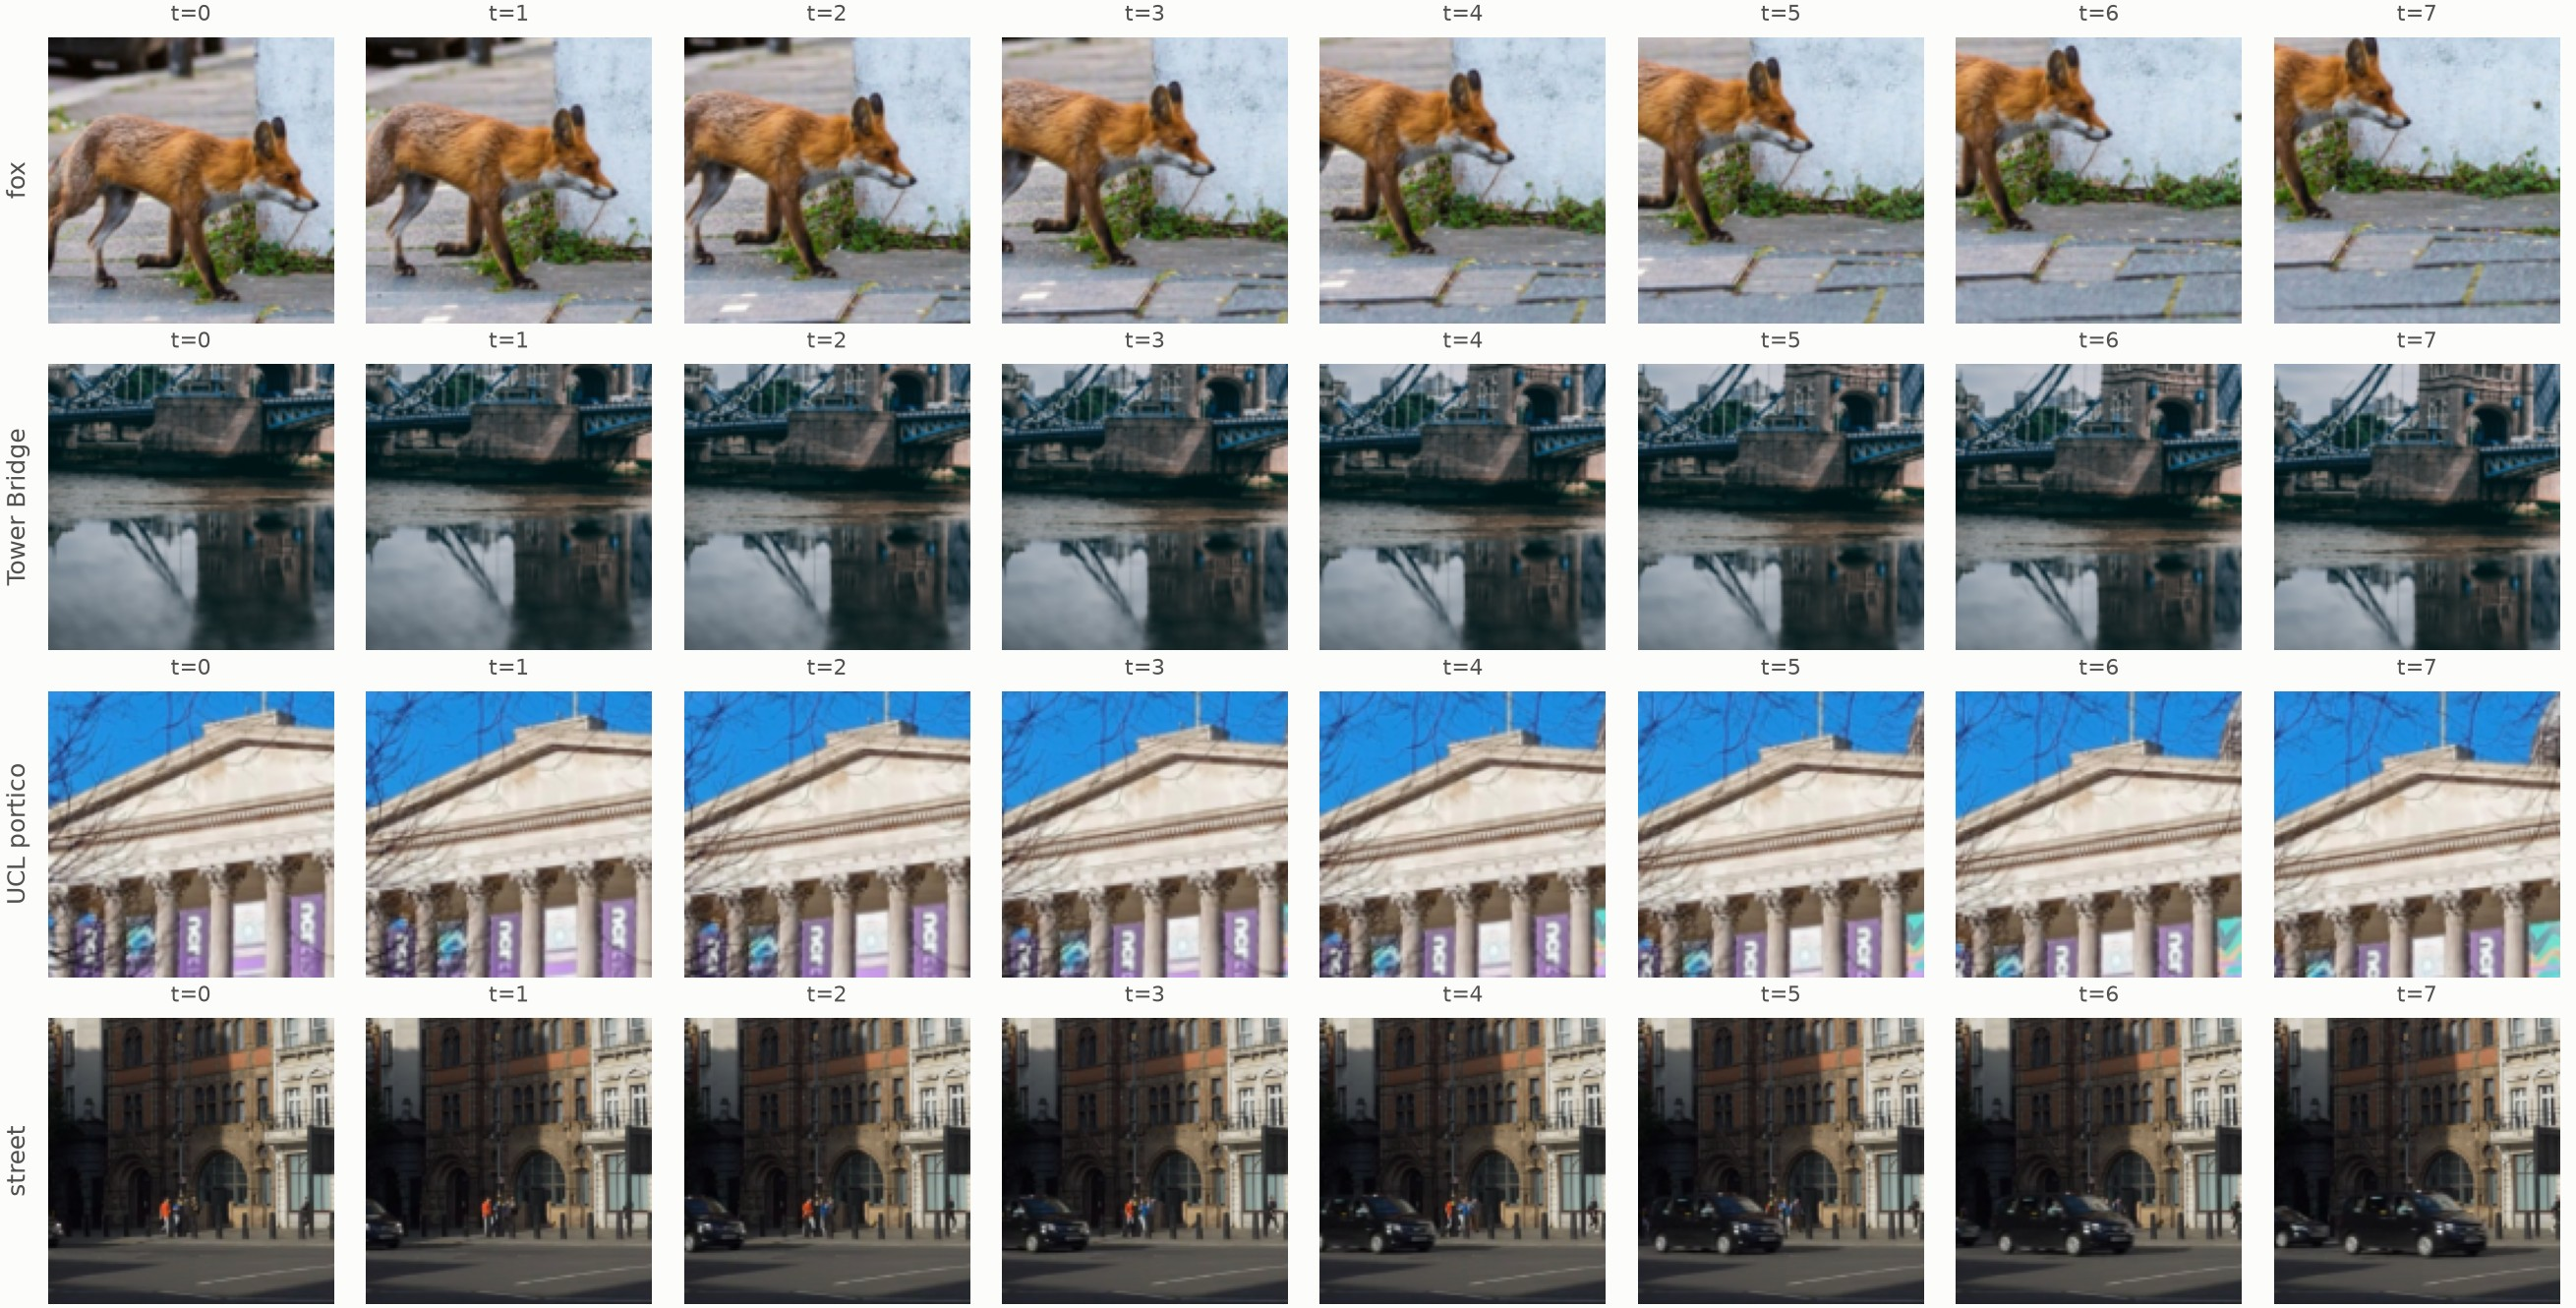

In [2]:
SCENES = {"fox": "fox.jpg", "Tower Bridge": "tower-bridge.jpg", "UCL portico": "ucl-portico.jpg", "street": "street.mp4"}
STREET = list(SCENES).index("street")  # the last scene, so a photo's scene id is also its index in photos


def load(path, size):
    """Every frame of a photo or video as (F, 3, *size) in [0, 1]."""
    if path.endswith(".mp4"):
        with av.open(f"assets/{path}") as container:
            frames = np.stack([frame.to_ndarray(format="rgb24") for frame in container.decode(video=0)])
    else:
        frames = np.array(Image.open(f"assets/{path}").convert("RGB"))[None]
    frames = torch.from_numpy(frames).permute(0, 3, 1, 2).float().div(255)
    return F.interpolate(frames, size=size, mode="bilinear", antialias=True).to(device)


photos = torch.cat([load(path, (384, 512)) for name, path in SCENES.items() if name != "street"])
street = load(SCENES["street"], (432, 768))


def window_grid(center, half, aspect, flip):
    """Sampling grid (n, T, SIZE, SIZE, 2) of square windows centered on center (n, T, 2).

    Coordinates are grid_sample's, where the frame spans [-1, 1]; half is half the window side (n, 1) relative to
    the frame height, aspect the frame's width over height (n, 1), and flip -1 to mirror a window, else 1 (n, 1).
    """
    u = torch.linspace(-1, 1, SIZE, device=device)
    square = torch.stack(torch.meshgrid(u, u, indexing="xy"), -1)
    scale = torch.cat([flip * half / aspect, half], 1)
    return center[:, :, None, None] + square * scale[:, None, None, None]


def sample(source, frame, grid):
    """Clips (n, 3, T, SIZE, SIZE) from the source frames indexed by frame (n, T), along grid."""
    clips = F.grid_sample(source[frame.flatten()], grid.flatten(0, 1), align_corners=False)
    return clips.unflatten(0, frame.shape).transpose(1, 2)


def london(n, generator=None, label=None):
    """Clips (n, 3, T, SIZE, SIZE) of a window on one scene, with their scene and region ids."""
    g = {"generator": generator, "device": device}
    label = torch.randint(len(SCENES), (n,), **g) if label is None else label.to(device)
    filmed = label == STREET
    aspect = torch.where(filmed, street.size(-1) / street.size(-2), photos.size(-1) / photos.size(-2))[:, None]

    half = 0.3 + 0.2 * torch.rand(n, 1, **g)
    extent = torch.cat([half / aspect, half], 1)  # the window's half-size in x and y
    travel = (2 * torch.rand(n, 2, **g) - 1) * extent * ~filmed[:, None]  # photo windows pan up to their own size
    position = 2 * torch.rand(n, 2, **g) - 1  # where the window sits in the room it has, from -1 to 1
    center = position * (1 - extent - travel.abs() / 2)
    path = center[:, None] + travel[:, None] * torch.linspace(-0.5, 0.5, FRAMES, device=device)[:, None]
    flip = torch.where(torch.rand(n, 1, **g) < 0.5, -1.0, 1.0)
    grid = window_grid(path, half, aspect, flip)

    start = (torch.rand(n, **g) * (len(street) - (FRAMES - 1) * STRIDE)).long()
    playing = start[:, None] + STRIDE * torch.arange(FRAMES, device=device)
    frame = torch.where(filmed[:, None], playing, label[:, None])  # a photo repeats its one frame
    clips = torch.empty(n, 3, FRAMES, SIZE, SIZE, device=device)
    clips[~filmed] = sample(photos, frame[~filmed], grid[~filmed])
    clips[filmed] = sample(street, frame[filmed], grid[filmed])

    region = 3 * label + ((position[:, 0] + 1) * 1.5).long().clamp(max=2)  # left, middle or right third
    return clips, label, region


clips, label, _ = london(4, label=torch.arange(4))
jpeg(plots.images(clips.transpose(1, 2).flatten(0, 1), [f"t={t}" for t in range(FRAMES)] * 4, size=1.6, rows=list(SCENES)))

## Views
One global view (80-100% of the frame, at 128 px) and four local views (25-50%, at 64 px). A view crops the same region of every frame, so all views cover the same moment. The encoder uses RoPE positions from each input's own grid, so the two sizes share it.

Every view is also color-jittered on its own. Without it, every crop of a clip shows the same color, and matching views by color is enough to solve the objective. The paper uses color jitter and grayscale for the same reason.

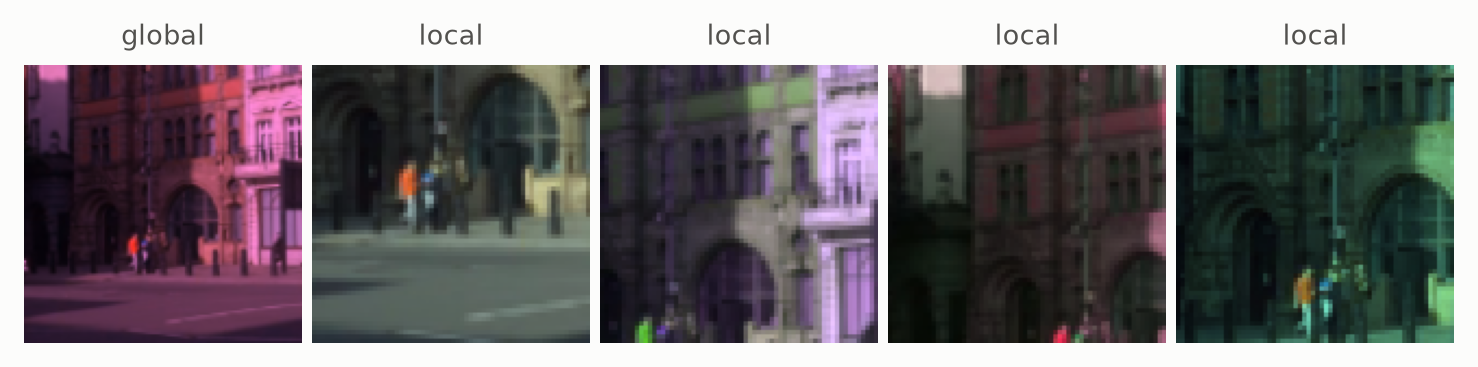

In [3]:
def crop(videos, scale, size):
    """The same random crop of every frame of videos (B, C, T, H, W), resized to size."""
    s = torch.empty(1).uniform_(*scale).sqrt().item()
    n = max(2, int(videos.size(-1) * s))
    i, j = torch.randint(0, videos.size(-1) - n + 1, (2,)).tolist()
    frames = videos[..., i : i + n, j : j + n].flatten(1, 2)
    return F.interpolate(frames, size=size, mode="bilinear", antialias=True).unflatten(1, videos.shape[1:3])


def jitter(videos):
    """Per-clip channel permutation and gains, and grayscale for 20% of clips."""
    B = videos.size(0)
    perm = torch.rand(B, 3, device=device).argsort(1)
    videos = videos.gather(1, perm[:, :, None, None, None].expand_as(videos))
    videos = videos * (0.6 + 0.8 * torch.rand(B, 3, 1, 1, 1, device=device))
    gray = torch.rand(B, 1, 1, 1, 1, device=device) < 0.2
    return torch.where(gray, videos.mean(1, keepdim=True).expand_as(videos), videos)


def views(videos):
    """One global view at SIZE and four local views at SIZE // 2, each jittered on its own."""
    return jitter(crop(videos, (0.8, 1.0), SIZE)), [jitter(crop(videos, (0.25, 0.5), SIZE // 2)) for _ in range(4)]


global_view, local_views = views(clips[STREET:])
frames = [global_view[0, :, 0]] + [F.interpolate(v[:, :, 0], size=SIZE)[0] for v in local_views]
plots.images(torch.stack(frames), ["global"] + ["local"] * 4, ncols=5)

## Train
A ViT with 6 blocks, one token per 8 x 8 patch of every frame. In training 90% of the patch tokens are dropped at random (the paper drops 95% of a 3136-token clip). The global view keeps 205 of its 2048 tokens and each local view 51 of 512.

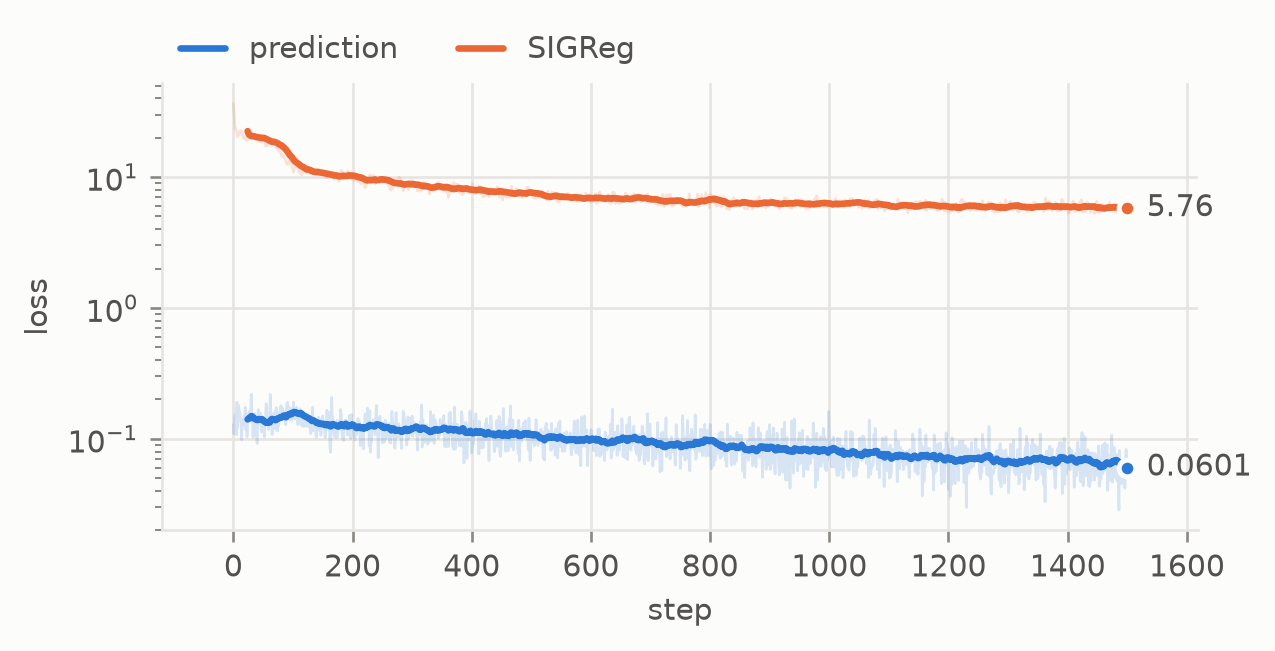

In [4]:
def make_encoder():
    return LeVJEPAEncoder(img_size=SIZE, patch_size=PATCH, embed_dim=192, depth=6, num_heads=6, num_frames=FRAMES, token_drop=0.9)


model = LeVJEPA(make_encoder(), MLP([192, 512, 64], norm=nn.BatchNorm1d), lamb=0.02).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.04, betas=(0.9, 0.95))

log = {"prediction": [], "SIGReg": []}
for step in range(1500):
    out = model(*views(london(128)[0]))
    opt.zero_grad()
    out["loss"].backward()
    opt.step()
    log["prediction"].append(out["pred_loss"].item())
    log["SIGReg"].append(out["sigreg_loss"].item())

plots.curves(log)

## Block-causal attention
A patch attends its own frame and earlier ones, and no patch attends `[cls]`. Changing the last frame of a clip leaves every token of the earlier frames unchanged, so a stream can be encoded one frame at a time. Only `[cls]`, which reads the whole clip, changes.

In [5]:
model.eval()
with torch.no_grad():
    clips = london(8)[0]
    edited = clips.clone()
    edited[:, :, -1] = edited[:, :, -1].flip(-1)
    a, b = model.encoder(clips), model.encoder(edited)
per_frame = (SIZE // PATCH) ** 2
change = (a[:, 1:] - b[:, 1:]).norm(dim=-1).unflatten(1, (FRAMES, per_frame)).amax(dim=(0, 2))
print("largest change of a patch token, by frame:", [f"{c:.1e}" for c in change.tolist()])
print(f"change of [cls]: {(a[:, 0] - b[:, 0]).norm(dim=-1).max():.2f}")

largest change of a patch token, by frame: ['0.0e+00', '0.0e+00', '0.0e+00', '0.0e+00', '0.0e+00', '0.0e+00', '0.0e+00', '2.0e+01']
change of [cls]: 0.20


## What the features know
LeVJEPA is evaluated on the frozen encoder. Three metrics on the `[cls]` embedding of 3072 fresh clips (2560 to fit, 512 to test), against the same encoder at random initialization:
- **linear probe**: classifies the scene (chance is 1/4) and the region (chance is 1/12);
- **k-NN**: the same labels by a weighted vote of the 20 nearest training clips, with no training at all;
- **RankMe**: the effective rank of the embeddings, out of 192 dimensions.

The test clips are color-jittered like the views. The four scenes differ so much in color that, on clean clips, even the random encoder tells them apart.

In [6]:
def embed(encoder, clips):
    """[cls] embeddings (N, D) of clips, 128 at a time."""
    with torch.no_grad():
        return torch.cat([encoder(c)[:, 0] for c in clips.split(128)])


def probe_scores(z, y, fit=2560):
    """Linear-probe and k-NN accuracy, fitting on the first fit embeddings and testing on the rest."""
    train, test = (z[:fit], y[:fit]), (z[fit:], y[fit:])
    return metrics.linear_probe(*train, *test).score, metrics.knn_accuracy(*train, *test).score


recompute_batchnorm(model, [london(128)[0] for _ in range(16)], lambda x: model.projector(model.encode(x)))
clips, scene, region = london(3072, generator=torch.Generator(device).manual_seed(7))
torch.manual_seed(11)
clips = torch.cat([jitter(c) for c in clips.split(128)])

print(f"{'':12s}{'scene: linear':>15s}{'k-NN':>7s}{'region: linear':>16s}{'k-NN':>7s}{'RankMe':>8s}")
for name, encoder in {"random init": make_encoder().to(device).eval(), "LeVJEPA": model.encoder}.items():
    z = embed(encoder, clips)
    scores = probe_scores(z, scene) + probe_scores(z, region)
    print(f"{name:12s}" + "".join(f"{s:{w}.1%}" for s, w in zip(scores, (15, 7, 16, 7))) + f"{metrics.rankme(z):8.1f}")

              scene: linear   k-NN  region: linear   k-NN  RankMe


random init           80.9%  63.3%           50.2%  32.8%     5.6


LeVJEPA              100.0% 100.0%           89.8%  83.6%    26.9


## Patch features
The [project page](https://levjepa.github.io/) shows the frozen encoder's patch tokens through PCA: their three leading components, as RGB. RoPE takes positions from the input's own grid, so the encoder reads a whole photo, 384 x 512 as one frame (48 x 64 patches), with no change. Each photo gets its own PCA.

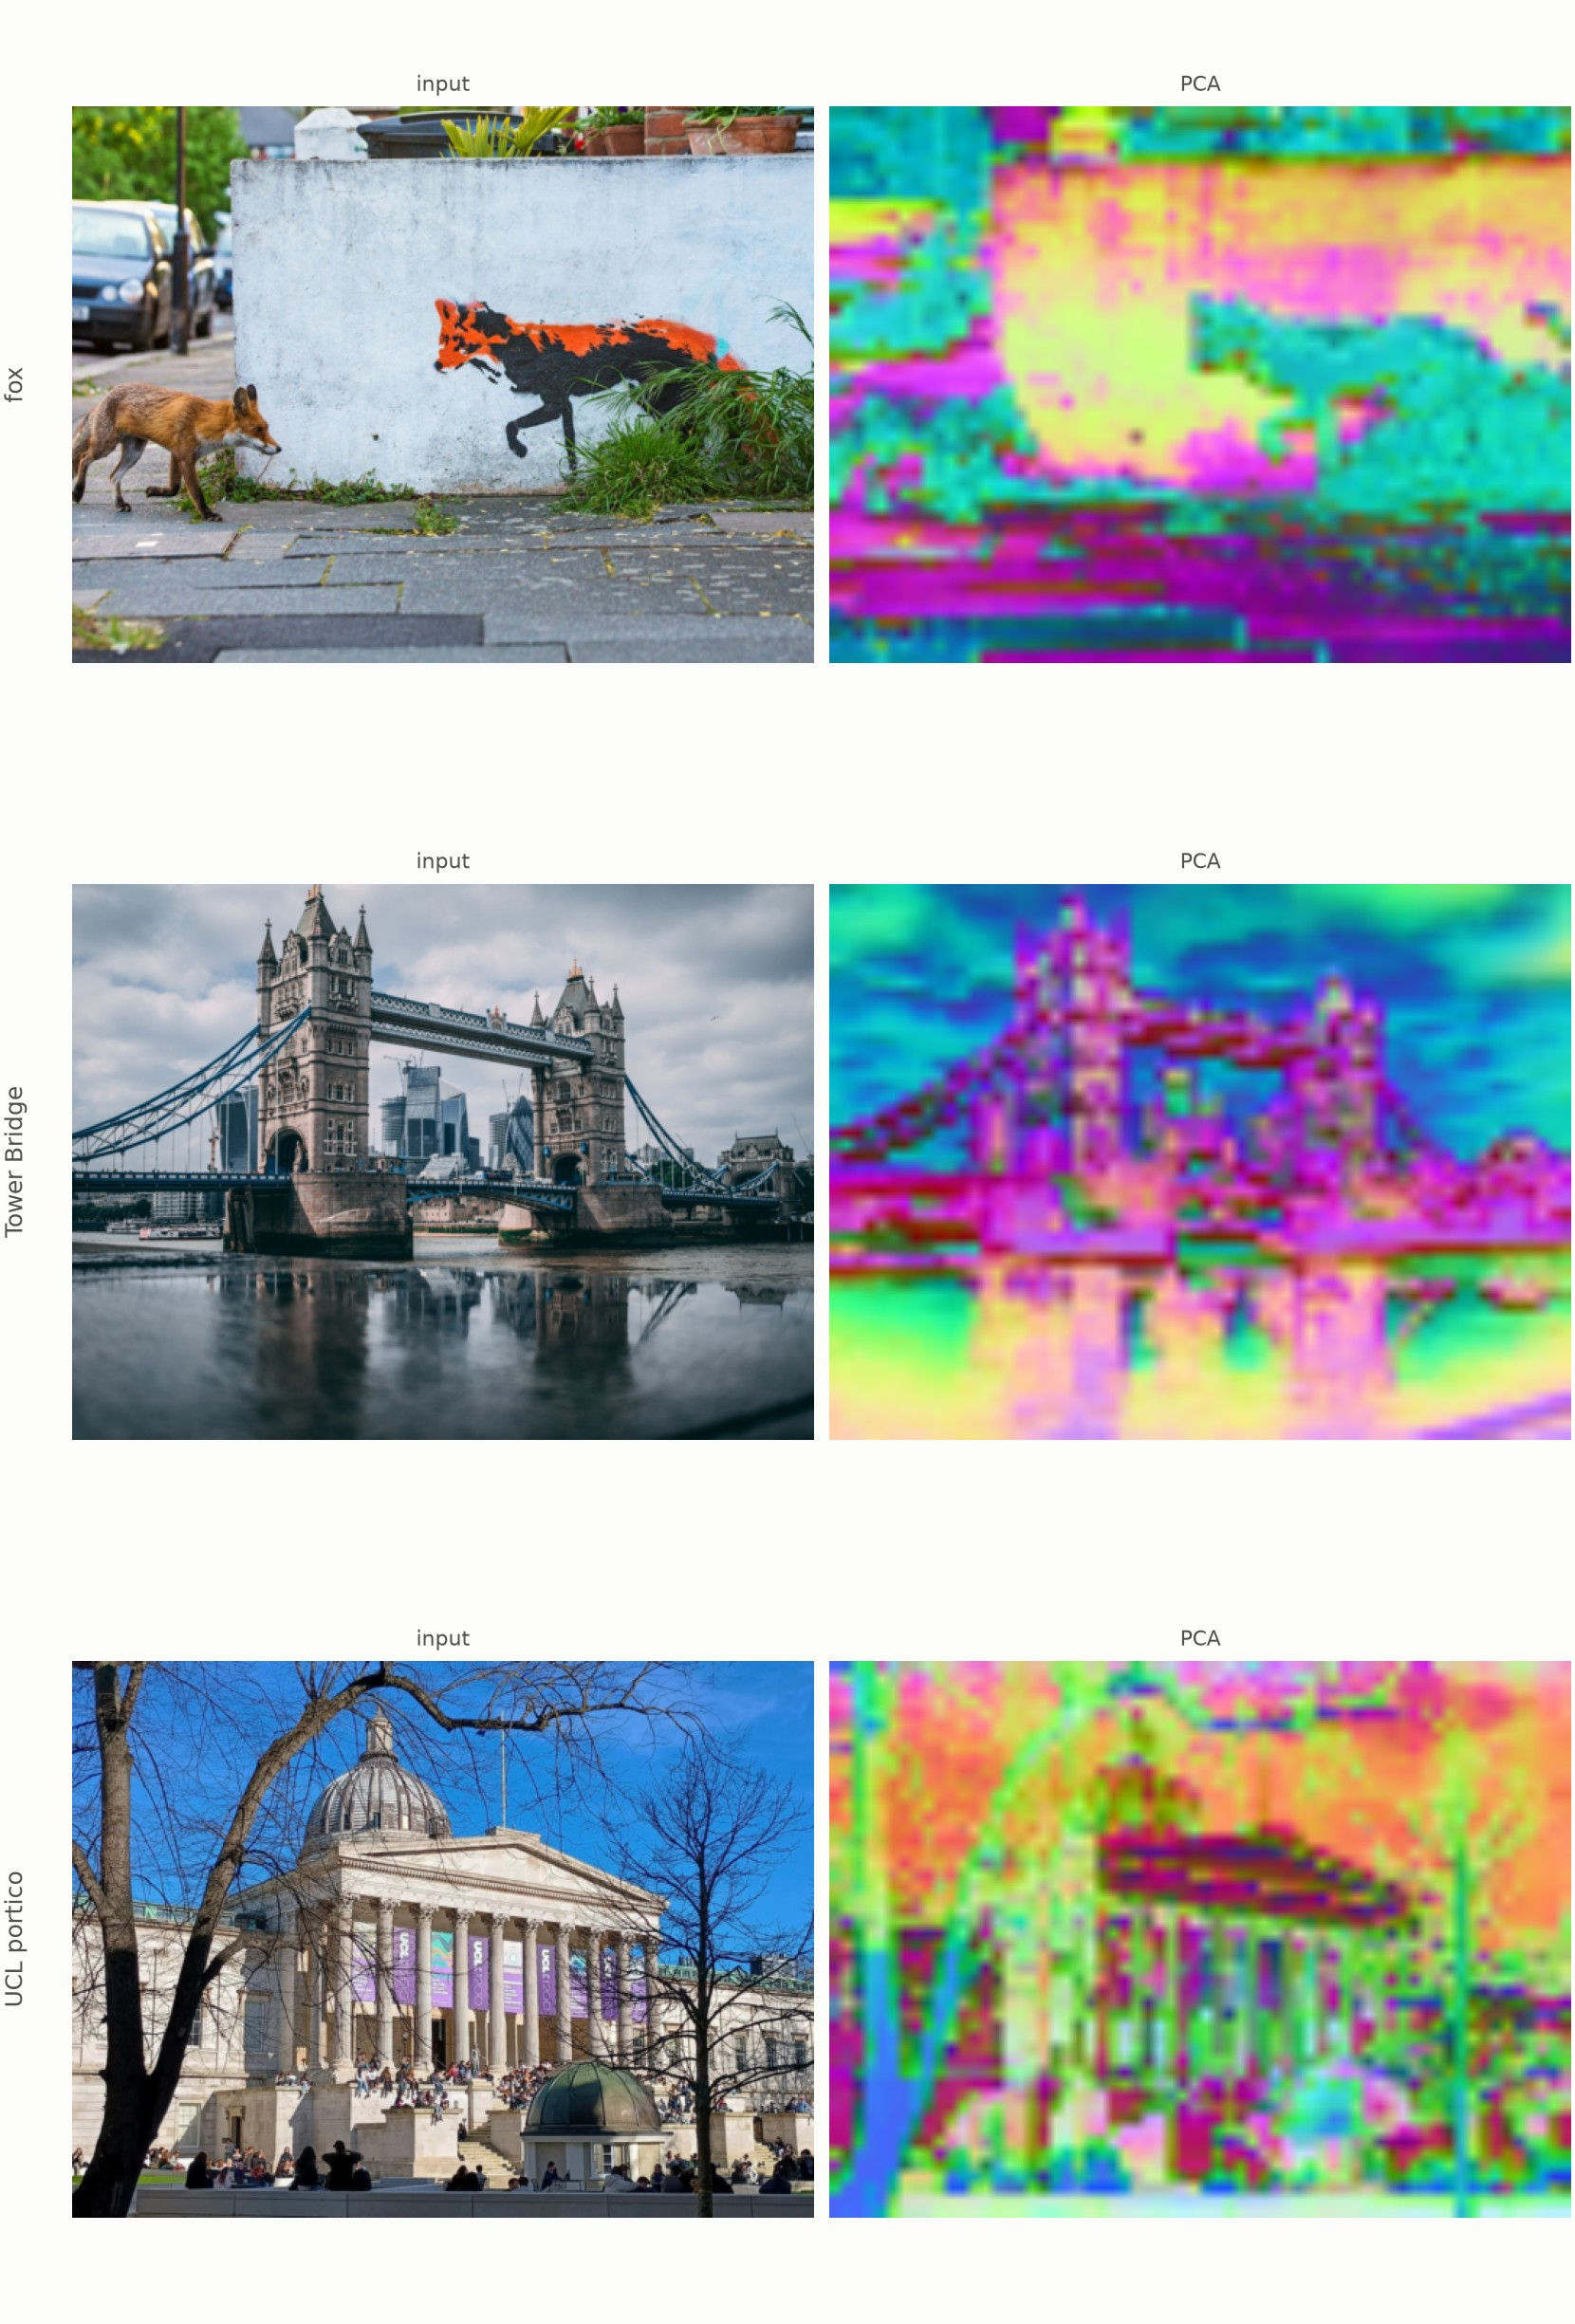

In [7]:
def patch_tokens(frames):
    """Patch tokens (T, h, w, D) of frames (T, 3, H, W), encoded FRAMES at a time."""
    with torch.no_grad():
        tokens = torch.cat([model.encoder(clip.transpose(0, 1)[None])[0, 1:] for clip in frames.split(FRAMES)])
    return tokens.view(len(frames), frames.size(-2) // PATCH, frames.size(-1) // PATCH, -1)


def pca_rgb(tokens):
    """The three leading principal components of tokens (..., D), each scaled to [0, 1], as (..., 3)."""
    flat = tokens.flatten(0, -2) - tokens.flatten(0, -2).mean(0)
    pcs = flat @ torch.pca_lowrank(flat, q=3, center=False)[2]
    lo, hi = pcs.quantile(0.01, dim=0), pcs.quantile(0.99, dim=0)
    return ((pcs - lo) / (hi - lo)).clamp(0, 1).view(*tokens.shape[:-1], 3)


def upsample(maps, size):
    """Maps (N, h, w, 3) to images (N, 3, *size)."""
    return F.interpolate(maps.permute(0, 3, 1, 2).float(), size=size, mode="bilinear", align_corners=False).clamp(0, 1)


pca = torch.cat([pca_rgb(patch_tokens(photo[None])) for photo in photos])
pairs = torch.stack([photos, upsample(pca, photos.shape[-2:])], 1).flatten(0, 1)
jpeg(plots.images(pairs, ["input", "PCA"] * len(photos), ncols=2, size=4, rows=list(SCENES)[:STREET]))

## Patch features on the street
The whole street footage at 432 x 768 (54 x 96 patches), where training saw 128 px windows of it. The encoder runs 8 frames at a time, the clip length it was trained on, and one PCA is fitted over every frame, so a color means the same thing throughout.

Left to right: the footage; the PCA, whose components stay put from frame to frame; and how far each patch token moves from the previous frame. The last lights up the buses and cars and stays dark on the static street. It follows where the pixels change, printed below as a correlation: these small features respond to motion, they do not identify objects.

In [8]:
frames = street[::STRIDE]
frames = frames[: len(frames) // FRAMES * FRAMES]  # (T, 3, 432, 768)
tokens = patch_tokens(frames)
pca = pca_rgb(tokens)


def pad_first(x):
    """Frame-to-frame differences (T - 1, ...) as (T, ...), the first frame repeating the second's."""
    return torch.cat([x[:1], x])


change = pad_first((tokens[1:] - tokens[:-1]).norm(dim=-1))
pixels = pad_first(F.avg_pool2d((frames[1:] - frames[:-1]).abs().mean(1, keepdim=True), PATCH)[:, 0])
print(f"correlation of token change with pixel change: {torch.corrcoef(torch.stack([change.flatten(), pixels.flatten()]))[0, 1]:.2f}")
heat = torch.from_numpy(colormaps["magma"]((change / change.quantile(0.995)).clamp(0, 1).cpu().numpy())[..., :3])

size = frames.shape[-2:]
video(frames, upsample(pca, size), upsample(heat, size))

correlation of token change with pixel change: 0.81
